In [1]:
import pandas as pd
import glob

files = glob.glob("*.txt")

print("Number of files found:", len(files))

Number of files found: 100


In [2]:
import pandas as pd
import glob

files = glob.glob("*.txt")

all_data = []

for file in files:
    df = pd.read_csv(
        file,
        header=None,
        names=["Taxi_ID","Timestamp","Longitude","Latitude"]
    )
    all_data.append(df)

data = pd.concat(all_data, ignore_index=True)

print(data.head())
print(data.shape)

   Taxi_ID            Timestamp  Longitude  Latitude
0        1  2008-02-02 15:36:08  116.51172  39.92123
1        1  2008-02-02 15:46:08  116.51135  39.93883
2        1  2008-02-02 15:46:08  116.51135  39.93883
3        1  2008-02-02 15:56:08  116.51627  39.91034
4        1  2008-02-02 16:06:08  116.47186  39.91248
(145582, 4)


In [3]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145582 entries, 0 to 145581
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Taxi_ID    145582 non-null  int64  
 1   Timestamp  145582 non-null  object 
 2   Longitude  145582 non-null  float64
 3   Latitude   145582 non-null  float64
dtypes: float64(2), int64(1), object(1)
memory usage: 4.4+ MB


In [4]:
data["Timestamp"] = pd.to_datetime(data["Timestamp"])

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145582 entries, 0 to 145581
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Taxi_ID    145582 non-null  int64         
 1   Timestamp  145582 non-null  datetime64[ns]
 2   Longitude  145582 non-null  float64       
 3   Latitude   145582 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1)
memory usage: 4.4 MB


In [6]:
#checking for duplicate data to check for overlapping data
data.duplicated().sum()

np.int64(7320)

In [7]:
#removing duplicates
data=data.drop_duplicates()

In [8]:
duplicates = data[data.duplicated()]

In [9]:
#checking of the duplicated data is deleted
duplicates.head()

,Taxi_ID,Timestamp,Longitude,Latitude


In [10]:
#verifying if all duplicates are delted
data.duplicated().sum()

np.int64(0)

In [11]:
data=data.sort_values(
    by=["Taxi_ID","Timestamp"]
)

In [12]:
data["Latitude"].shift(1)

0            NaN
1       39.92123
3       39.93883
4       39.91034
5       39.91248
          ...   
7523    39.87683
7524    39.87015
7525    39.87374
7526    39.87478
7527    39.87172
Name: Latitude, Length: 138262, dtype: float64

In [13]:
data["Prev_Latitude"] = data["Latitude"].shift(1)
#we created nre column  prev latitude.we need oth the current and orev latitude.

In [14]:
data.head()

,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude
0,1,2008-02-02 15:36:08,116.51172,39.92123,NaN
1,1,2008-02-02 15:46:08,116.51135,39.93883,39.92123
3,1,2008-02-02 15:56:08,116.51627,39.91034,39.93883
4,1,2008-02-02 16:06:08,116.47186,39.91248,39.91034
5,1,2008-02-02 16:16:08,116.47217,39.92498,39.91248


In [15]:
#done with data cleaning
data = data.fillna(0)

In [16]:
#FEATURE ENGINEERING
data["Prev_Longitude"]=data["Longitude"].shift(1)
data["Prev_Timestamp"]=data["Timestamp"].shift(1)

In [17]:
data.head()

,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp
0,1,2008-02-02 15:36:08,116.51172,39.92123,0.00000,NaN,NaT
1,1,2008-02-02 15:46:08,116.51135,39.93883,39.92123,116.51172,2008-02-02 15:36:08
3,1,2008-02-02 15:56:08,116.51627,39.91034,39.93883,116.51135,2008-02-02 15:46:08
4,1,2008-02-02 16:06:08,116.47186,39.91248,39.91034,116.51627,2008-02-02 15:56:08
5,1,2008-02-02 16:16:08,116.47217,39.92498,39.91248,116.47186,2008-02-02 16:06:08


In [18]:
data.columns.tolist()

['Taxi_ID',
 'Timestamp',
 'Longitude',
 'Latitude',
 'Prev_Latitude',
 'Prev_Longitude',
 'Prev_Timestamp']

In [19]:
data["Prev_Longitude"] = data["Longitude"].shift(1)

In [20]:
#implementing haversine formula in py
import math
print(math.sin(math.radians(90)))

1.0


In [21]:
#converting radians into degrees
import numpy as np

data["Latitude_rad"] = np.radians(data["Latitude"])
data["Longitude_rad"] = np.radians(data["Longitude"])

data["Prev_Latitude_rad"] = np.radians(data["Prev_Latitude"])
data["Prev_Longitude_rad"] = np.radians(data["Prev_Longitude"])

In [22]:
data.head()

,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp,Latitude_rad,Longitude_rad,Prev_Latitude_rad,Prev_Longitude_rad
0,1,2008-02-02 15:36:08,116.51172,39.92123,0.00000,NaN,NaT,0.696757,2.033513,0.000000,NaN
1,1,2008-02-02 15:46:08,116.51135,39.93883,39.92123,116.51172,2008-02-02 15:36:08,0.697064,2.033507,0.696757,2.033513
3,1,2008-02-02 15:56:08,116.51627,39.91034,39.93883,116.51135,2008-02-02 15:46:08,0.696567,2.033593,0.697064,2.033507
4,1,2008-02-02 16:06:08,116.47186,39.91248,39.91034,116.51627,2008-02-02 15:56:08,0.696604,2.032817,0.696567,2.033593
5,1,2008-02-02 16:16:08,116.47217,39.92498,39.91248,116.47186,2008-02-02 16:06:08,0.696822,2.032823,0.696604,2.032817


In [23]:
data["Delta_Lat"]=data["Latitude_rad"]-data["Prev_Latitude_rad"]
data["Delta_Lon"]=data["Longitude_rad"]-data["Prev_Longitude_rad"]

In [24]:
data["a"] = (
    np.sin(data["Delta_Lat"] / 2) ** 2
) 

In [25]:
data["a"] = (
    np.sin(data["Delta_Lat"] / 2) ** 2
    + np.cos(data["Prev_Latitude_rad"])
      * np.cos(data["Latitude_rad"])
      * np.sin(data["Delta_Lon"] / 2) ** 2
)

In [26]:
#checking max valu of a
print(data["a"].max())

0.6718816331017556


In [27]:
#checking min value of a
print(data["a"].min())

0.0


In [28]:
data[data["a"] > 1]

,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp,Latitude_rad,Longitude_rad,Prev_Latitude_rad,Prev_Longitude_rad,Delta_Lat,Delta_Lon,a


In [29]:
print(data["a"].max())

print(data["a"].min())

data[data["a"] > 1]

0.6718816331017556
0.0


,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp,Latitude_rad,Longitude_rad,Prev_Latitude_rad,Prev_Longitude_rad,Delta_Lat,Delta_Lon,a


In [30]:
print(data["a"].max())

print(data["a"].min())

data[data["a"] > 1]

0.6718816331017556
0.0


,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp,Latitude_rad,Longitude_rad,Prev_Latitude_rad,Prev_Longitude_rad,Delta_Lat,Delta_Lon,a


In [31]:
data.columns.tolist()

['Taxi_ID',
 'Timestamp',
 'Longitude',
 'Latitude',
 'Prev_Latitude',
 'Prev_Longitude',
 'Prev_Timestamp',
 'Latitude_rad',
 'Longitude_rad',
 'Prev_Latitude_rad',
 'Prev_Longitude_rad',
 'Delta_Lat',
 'Delta_Lon',
 'a']

In [32]:
# ----------------------------
# Haversine Distance Calculation
# ----------------------------

# Calculate the central angle
data["c"] = 2 * np.arctan2(
    np.sqrt(data["a"]),
    np.sqrt(1 - data["a"])
)

# Earth's radius in kilometers
EARTH_RADIUS = 6371

# Calculate distance
data["Distance_km"] = EARTH_RADIUS * data["c"]

In [33]:
data[["Distance_km"]].head()

,Distance_km
0,NaN
1,1.957285
3,3.195604
4,3.795226
5,1.390188


In [34]:
data["Distance_km"].describe()

count    138261.000000
mean          1.548562
std          52.490205
min           0.000000
25%           0.006726
50%           0.224782
75%           1.160189
max       12243.264088
Name: Distance_km, dtype: float64

In [35]:
data.nlargest(10, "Distance_km")[
    ["Taxi_ID", "Timestamp", "Prev_Timestamp", "Distance_km"]
]

,Taxi_ID,Timestamp,Prev_Timestamp,Distance_km
91424,62,2008-02-03 01:45:27,2008-02-03 01:40:32,12243.264088
91423,62,2008-02-03 01:40:32,2008-02-02 22:33:38,12232.353893
87948,60,2008-02-02 18:49:53,2008-02-02 18:46:04,2364.384053
87950,60,2008-02-02 18:54:53,2008-02-02 18:49:53,2364.058805
31111,26,2008-02-07 06:40:52,2008-02-07 06:40:49,2362.622420
31112,26,2008-02-07 06:45:51,2008-02-07 06:40:52,2359.432792
15588,16,2008-02-08 12:25:57,2008-02-08 12:25:17,1975.883073
15586,16,2008-02-08 12:25:17,2008-02-08 12:25:08,1975.811460
14734,16,2008-02-05 16:39:39,2008-02-05 16:39:34,1958.478824
14736,16,2008-02-05 16:39:49,2008-02-05 16:39:39,1958.431335


In [36]:
data.loc[data["Distance_km"].idxmax()]

Taxi_ID                                62
Timestamp             2008-02-03 01:45:27
Longitude                       116.71903
Latitude                         40.13113
Prev_Latitude                         0.0
Prev_Longitude                        0.0
Prev_Timestamp        2008-02-03 01:40:32
Latitude_rad                      0.70042
Longitude_rad                    2.037131
Prev_Latitude_rad                     0.0
Prev_Longitude_rad                    0.0
Delta_Lat                         0.70042
Delta_Lon                        2.037131
a                                0.671882
c                                1.921718
Distance_km                  12243.264088
Name: 91424, dtype: object

In [37]:
data[
(data["Prev_Latitude"]== 0) |
(data["Prev_Longitude"]==0)
]

,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp,Latitude_rad,Longitude_rad,Prev_Latitude_rad,Prev_Longitude_rad,Delta_Lat,Delta_Lon,a,c,Distance_km
0,1,2008-02-02 15:36:08,116.51172,39.92123,0.0,NaN,NaT,0.696757,2.033513,0.0,NaN,0.696757,NaN,NaN,NaN,NaN
91424,62,2008-02-03 01:45:27,116.71903,40.13113,0.0,0.0,2008-02-03 01:40:32,0.700420,2.037131,0.0,0.0,0.700420,2.037131,0.671882,1.921718,12243.264088


In [38]:
data[
    (data["Prev_Latitude"] == 0) |
    (data["Prev_Longitude"] == 0)
][
    ["Taxi_ID","Latitude","Longitude","Prev_Latitude","Prev_Longitude"]
].head(20)

,Taxi_ID,Latitude,Longitude,Prev_Latitude,Prev_Longitude
0,1,39.92123,116.51172,0.0,NaN
91424,62,40.13113,116.71903,0.0,0.0


In [39]:
data[
    (data["Prev_Latitude"] == 0) |
    (data["Prev_Longitude"] == 0)
].shape

(2, 16)

In [40]:
data = data.fillna(0)

In [41]:
data[
    (data["Latitude"] == 0) |
    (data["Longitude"] == 0)
]

,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp,Latitude_rad,Longitude_rad,Prev_Latitude_rad,Prev_Longitude_rad,Delta_Lat,Delta_Lon,a,c,Distance_km
91423,62,2008-02-03 01:40:32,0.0,0.0,39.90657,116.48999,2008-02-02 22:33:38,0.0,0.0,0.696501,2.033134,-0.696501,-2.033134,0.671077,1.920005,12232.353893


In [42]:
#removing invalid GPS co-ordinates (0,0) 
data = data[
 (data["Latitude"] !=0)&
 (data["Longitude"] !=0)
].copy()

In [43]:
print(data["Distance_km"].describe())

count    138261.000000
mean          1.460089
std          40.905353
min           0.000000
25%           0.006726
50%           0.224776
75%           1.160136
max       12243.264088
Name: Distance_km, dtype: float64


In [44]:
print(data["Distance_km"].max())

12243.264087961827


In [45]:
data = data[
    (data["Latitude"] != 0) &
    (data["Longitude"] != 0)
].copy()

print(data.shape)

(138261, 16)


In [46]:
print(data.shape)

print((data["Latitude"] == 0).sum())

print((data["Longitude"] == 0).sum())

(138261, 16)
0
0


In [47]:
data.loc[data["Latitude"] == 0, ["Taxi_ID", "Latitude", "Longitude"]]

,Taxi_ID,Latitude,Longitude


In [48]:

data.loc[data["Distance_km"].idxmax()]

Taxi_ID                                62
Timestamp             2008-02-03 01:45:27
Longitude                       116.71903
Latitude                         40.13113
Prev_Latitude                         0.0
Prev_Longitude                        0.0
Prev_Timestamp        2008-02-03 01:40:32
Latitude_rad                      0.70042
Longitude_rad                    2.037131
Prev_Latitude_rad                     0.0
Prev_Longitude_rad                    0.0
Delta_Lat                         0.70042
Delta_Lon                        2.037131
a                                0.671882
c                                1.921718
Distance_km                  12243.264088
Name: 91424, dtype: object

In [49]:
(data["Latitude"] == 0).sum()

np.int64(0)

In [50]:
data.iloc[91423]

Taxi_ID                                64
Timestamp             2008-02-08 12:57:45
Longitude                        116.3914
Latitude                         39.95065
Prev_Latitude                    39.95019
Prev_Longitude                  116.40254
Prev_Timestamp        2008-02-08 12:52:43
Latitude_rad                      0.69727
Longitude_rad                    2.031413
Prev_Latitude_rad                0.697262
Prev_Longitude_rad               2.031608
Delta_Lat                        0.000008
Delta_Lon                       -0.000194
a                                     0.0
c                                0.000149
Distance_km                      0.950973
Name: 96015, dtype: object

In [51]:
print(data.index.min(), data.index.max())

print(data.loc[data["Distance_km"].idxmax(), [
    "Taxi_ID",
    "Latitude",
    "Longitude",
    "Prev_Latitude",
    "Prev_Longitude"
]])

0 145581
Taxi_ID                  62
Latitude           40.13113
Longitude         116.71903
Prev_Latitude           0.0
Prev_Longitude          0.0
Name: 91424, dtype: object


In [52]:
print(data["Distance_km"].idxmax())

91424


In [53]:
cols = [
    "Prev_Latitude",
    "Prev_Longitude",
    "Prev_Timestamp",
    "Latitude_rad",
    "Longitude_rad",
    "Prev_Latitude_rad",
    "Prev_Longitude_rad",
    "Delta_Lat",
    "Delta_Lon",
    "a",
    "c",
    "Distance_km"
]

data = data.drop(columns=cols, errors="ignore")

In [54]:
#we are feture engineering things again bcoz we messed up mean and actual distance bw two points we are re engineering our features like latitude mean prev lat etccc....................
#..........................................................
print(data.columns.tolist())

['Taxi_ID', 'Timestamp', 'Longitude', 'Latitude']


In [55]:
# ----------------------------
# Create Previous GPS Position
# ----------------------------

data = data.sort_values(["Taxi_ID", "Timestamp"])

data["Prev_Latitude"] = data.groupby("Taxi_ID")["Latitude"].shift(1)
data["Prev_Longitude"] = data.groupby("Taxi_ID")["Longitude"].shift(1)
data["Prev_Timestamp"] = data.groupby("Taxi_ID")["Timestamp"].shift(1)

In [56]:
data.head()

,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp
0,1,2008-02-02 15:36:08,116.51172,39.92123,NaN,NaN,NaT
1,1,2008-02-02 15:46:08,116.51135,39.93883,39.92123,116.51172,2008-02-02 15:36:08
3,1,2008-02-02 15:56:08,116.51627,39.91034,39.93883,116.51135,2008-02-02 15:46:08
4,1,2008-02-02 16:06:08,116.47186,39.91248,39.91034,116.51627,2008-02-02 15:56:08
5,1,2008-02-02 16:16:08,116.47217,39.92498,39.91248,116.47186,2008-02-02 16:06:08


In [57]:
print(data.isnull().sum())

Taxi_ID             0
Timestamp           0
Longitude           0
Latitude            0
Prev_Latitude     100
Prev_Longitude    100
Prev_Timestamp    100
dtype: int64


In [58]:
# ----------------------------
# Convert GPS Coordinates to Radians
# ----------------------------

import numpy as np

data["Latitude_rad"] = np.radians(data["Latitude"])
data["Longitude_rad"] = np.radians(data["Longitude"])

data["Prev_Latitude_rad"] = np.radians(data["Prev_Latitude"])
data["Prev_Longitude_rad"] = np.radians(data["Prev_Longitude"])

In [59]:
data[[
    "Latitude",
    "Latitude_rad",
    "Prev_Latitude",
    "Prev_Latitude_rad"
]].head()

,Latitude,Latitude_rad,Prev_Latitude,Prev_Latitude_rad
0,39.92123,0.696757,NaN,NaN
1,39.93883,0.697064,39.92123,0.696757
3,39.91034,0.696567,39.93883,0.697064
4,39.91248,0.696604,39.91034,0.696567
5,39.92498,0.696822,39.91248,0.696604


In [60]:
# ----------------------------
# Calculate Angular Difference
# ----------------------------

data["Delta_Lat"] = data["Latitude_rad"] - data["Prev_Latitude_rad"]
data["Delta_Lon"] = data["Longitude_rad"] - data["Prev_Longitude_rad"]

In [61]:
data[[
    "Delta_Lat",
    "Delta_Lon"
]].head()

,Delta_Lat,Delta_Lon
0,NaN,NaN
1,0.000307,-0.000006
3,-0.000497,0.000086
4,0.000037,-0.000775
5,0.000218,0.000005


In [62]:
# ----------------------------
# Calculate Haversine Distance
# ----------------------------

# Step 1: Calculate 'a'
data["a"] = (
    np.sin(data["Delta_Lat"] / 2) ** 2
    + np.cos(data["Prev_Latitude_rad"])
    * np.cos(data["Latitude_rad"])
    * np.sin(data["Delta_Lon"] / 2) ** 2
)

# Step 2: Calculate central angle
data["c"] = 2 * np.arctan2(
    np.sqrt(data["a"]),
    np.sqrt(1 - data["a"])
)

# Step 3: Calculate distance in kilometers
EARTH_RADIUS = 6371

data["Distance_km"] = EARTH_RADIUS * data["c"]

In [63]:
print(data["Distance_km"].describe())

print(data["Distance_km"].max())

count    138161.000000
mean          1.352228
std          24.263717
min           0.000000
25%           0.006726
50%           0.224223
75%           1.157306
max        2364.384053
Name: Distance_km, dtype: float64
2364.384052520793


In [64]:
data.loc[data["Distance_km"].idxmax()]

Taxi_ID                                60
Timestamp             2008-02-02 18:49:53
Longitude                       109.53417
Latitude                         19.53645
Prev_Latitude                    39.98473
Prev_Longitude                  116.32433
Prev_Timestamp        2008-02-02 18:46:04
Latitude_rad                     0.340975
Longitude_rad                    1.911732
Prev_Latitude_rad                0.697865
Prev_Longitude_rad               2.030243
Delta_Lat                        -0.35689
Delta_Lon                       -0.118511
a                                0.034039
c                                0.371117
Distance_km                   2364.384053
Name: 87948, dtype: object

In [65]:
# ----------------------------
# Calculate Time Difference
# ----------------------------

data["Time_Diff_Min"] = (
    data["Timestamp"] - data["Prev_Timestamp"]
).dt.total_seconds() / 60

In [66]:
data[[
    "Timestamp",
    "Prev_Timestamp",
    "Time_Diff_Min"
]].head()

,Timestamp,Prev_Timestamp,Time_Diff_Min
0,2008-02-02 15:36:08,NaT,NaN
1,2008-02-02 15:46:08,2008-02-02 15:36:08,10.0
3,2008-02-02 15:56:08,2008-02-02 15:46:08,10.0
4,2008-02-02 16:06:08,2008-02-02 15:56:08,10.0
5,2008-02-02 16:16:08,2008-02-02 16:06:08,10.0


In [67]:
# Calculate Speed (km/h)
data["Speed_kmh"] = data["Distance_km"] / (data["Time_Diff_Min"] / 60)

In [68]:
print(data["Speed_kmh"].describe())

print(data["Speed_kmh"].max())

count    1.381610e+05
mean              inf
std               NaN
min      0.000000e+00
25%      1.436023e-01
50%      1.099972e+01
75%      2.407489e+01
max               inf
Name: Speed_kmh, dtype: float64
inf


In [69]:
data.groupby("Taxi_ID").shift(1)

,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp,Latitude_rad,Longitude_rad,Prev_Latitude_rad,Prev_Longitude_rad,Delta_Lat,Delta_Lon,a,c,Distance_km,Time_Diff_Min,Speed_kmh
0,NaT,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2008-02-02 15:36:08,116.51172,39.92123,NaN,NaN,NaT,0.696757,2.033513,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2008-02-02 15:46:08,116.51135,39.93883,39.92123,116.51172,2008-02-02 15:36:08,0.697064,2.033507,0.696757,2.033513,0.000307,-0.000006,2.359570e-08,0.000307,1.957285,10.000000,11.743710
4,2008-02-02 15:56:08,116.51627,39.91034,39.93883,116.51135,2008-02-02 15:46:08,0.696567,2.033593,0.697064,2.033507,-0.000497,0.000086,6.289713e-08,0.000502,3.195604,10.000000,19.173626
5,2008-02-02 16:06:08,116.47186,39.91248,39.91034,116.51627,2008-02-02 15:56:08,0.696604,2.032817,0.696567,2.033593,0.000037,-0.000775,8.871560e-08,0.000596,3.795226,10.000000,22.771354
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7523,2008-02-08 15:16:03,116.47791,39.87683,39.87951,116.48336,2008-02-08 15:14:17,0.695982,2.032923,0.696029,2.033018,-0.000047,-0.000095,1.879087e-09,0.000087,0.552346,1.766667,18.758914
7524,2008-02-08 15:19:18,116.46956,39.87015,39.87683,116.47791,2008-02-08 15:16:03,0.695865,2.032777,0.695982,2.032923,-0.000117,-0.000146,6.525575e-09,0.000162,1.029312,3.250000,19.002681
7525,2008-02-08 15:21:04,116.46167,39.87374,39.87015,116.46956,2008-02-08 15:19:18,0.695928,2.032640,0.695865,2.032777,0.000063,-0.000138,3.773913e-09,0.000123,0.782769,1.766667,26.584601
7526,2008-02-08 15:24:20,116.46944,39.87478,39.87374,116.46167,2008-02-08 15:21:04,0.695946,2.032775,0.695928,2.032640,0.000018,0.000136,2.790319e-09,0.000106,0.673077,3.266667,12.362631


In [70]:
# ----------------------------
# Detect Idle Vehicles
# ----------------------------

IDLE_THRESHOLD = 1  # km/h

data["Is_Idle"] = (
    data["Speed_kmh"] < IDLE_THRESHOLD
).astype(int)

print(data["Is_Idle"].value_counts())

Is_Idle
0    94445
1    43816
Name: count, dtype: int64


In [71]:
print(data["Is_Idle"].value_counts())

print("\nIdle percentage:")

print(
    (data["Is_Idle"].mean() * 100).round(2),
    "%"
)

Is_Idle
0    94445
1    43816
Name: count, dtype: int64

Idle percentage:
31.69 %


In [72]:
# ----------------------------
# Calculate Bearing (Direction)
# ----------------------------

y = np.sin(data["Delta_Lon"]) * np.cos(data["Latitude_rad"])

x = (
    np.cos(data["Prev_Latitude_rad"]) * np.sin(data["Latitude_rad"])
    - np.sin(data["Prev_Latitude_rad"])
    * np.cos(data["Latitude_rad"])
    * np.cos(data["Delta_Lon"])
)

data["Bearing"] = np.degrees(np.arctan2(y, x))

# Convert from (-180, 180] to (0, 360)
data["Bearing"] = (data["Bearing"] + 360) % 360

In [73]:
# ----------------------------
# Time-Based Features
# ----------------------------

data["Hour"] = data["Timestamp"].dt.hour
data["DayOfWeek"] = data["Timestamp"].dt.dayofweek

# Monday = 0, Sunday = 6
data["IsWeekend"] = data["DayOfWeek"].isin([5, 6]).astype(int)

# Rush Hour:
# Morning: 7–10 AM
# Evening: 4–7 PM
data["RushHour"] = (
    ((data["Hour"] >= 7) & (data["Hour"] <= 10)) |
    ((data["Hour"] >= 16) & (data["Hour"] <= 19))
).astype(int)

In [74]:
print(data[["Hour", "DayOfWeek", "IsWeekend", "RushHour"]].head())

   Hour  DayOfWeek  IsWeekend  RushHour
0    15          5          1         0
1    15          5          1         0
3    15          5          1         0
4    16          5          1         1
5    16          5          1         1


In [75]:
print(data["Speed_kmh"].describe())

print(data["Speed_kmh"].quantile([0.95, 0.99, 0.999]))

count    1.381610e+05
mean              inf
std               NaN
min      0.000000e+00
25%      1.436023e-01
50%      1.099972e+01
75%      2.407489e+01
max               inf
Name: Speed_kmh, dtype: float64
0.950      52.848930
0.990      78.838316
0.999    3084.545207
Name: Speed_kmh, dtype: float64


In [76]:
data[data["Speed_kmh"] > 120][
    ["Taxi_ID", "Timestamp", "Speed_kmh", "Distance_km", "Time_Diff_Min"]
].head(20)

,Taxi_ID,Timestamp,Speed_kmh,Distance_km,Time_Diff_Min
20138,2,2008-02-02 18:03:05,27496.249913,7.637847,0.016667
20139,2,2008-02-02 18:03:49,624.914771,7.637847,0.733333
21191,2,2008-02-06 17:42:14,307.461184,6.405441,1.250000
21193,2,2008-02-06 17:46:01,126.438330,7.972639,3.783333
41397,3,2008-02-04 16:41:26,155.530515,11.967209,4.616667
41398,3,2008-02-04 16:41:49,1801.650672,11.510546,0.383333
41417,3,2008-02-04 18:16:38,282.793035,22.780550,4.833333
41419,3,2008-02-04 18:16:48,8583.962944,23.844342,0.166667
42157,3,2008-02-08 12:00:07,1476.601676,115.256964,4.683333
42159,3,2008-02-08 12:00:25,23179.997499,115.899987,0.300000


In [77]:
# ----------------------------
# Detect GPS Speed Anomalies
# ----------------------------

SPEED_THRESHOLD = 120

data["GPS_Anomaly"] = (data["Speed_kmh"] > SPEED_THRESHOLD).astype(int)

print("Total GPS Anomalies:", data["GPS_Anomaly"].sum())

Total GPS Anomalies: 605


In [78]:
data["GPS_Anomaly"].value_counts()

GPS_Anomaly
0    137656
1       605
Name: count, dtype: int64

In [79]:
#creating new dataframe,this is **model_data** = clean dataset for ML
model_data= data[data["GPS_Anomaly"]==0].copy()

In [80]:
#starting FEATURES 2.0 vecause we accidentallyd elted our features


In [81]:
# ----------------------------------
# Sort GPS data by taxi and time
# ----------------------------------

data = data.sort_values(
    ["Taxi_ID", "Timestamp"]
).reset_index(drop=True)

# Previous GPS point for each taxi
data["Prev_Latitude"] = data.groupby("Taxi_ID")["Latitude"].shift(1)
data["Prev_Longitude"] = data.groupby("Taxi_ID")["Longitude"].shift(1)
data["Prev_Timestamp"] = data.groupby("Taxi_ID")["Timestamp"].shift(1)

# Time difference in minutes
data["Time_Diff_Min"] = (
    data["Timestamp"] - data["Prev_Timestamp"]
).dt.total_seconds() / 60

print("Shape:", data.shape)

print("\nMissing previous points:")
print(data[[
    "Prev_Latitude",
    "Prev_Longitude",
    "Prev_Timestamp",
    "Time_Diff_Min"
]].isna().sum())

Shape: (138261, 25)

Missing previous points:
Prev_Latitude     100
Prev_Longitude    100
Prev_Timestamp    100
Time_Diff_Min     100
dtype: int64


In [82]:
# ----------------------------------
# Calculate distance between GPS points
# ----------------------------------

import numpy as np

data["Latitude_rad"] = np.radians(data["Latitude"])
data["Longitude_rad"] = np.radians(data["Longitude"])

data["Prev_Latitude_rad"] = np.radians(data["Prev_Latitude"])
data["Prev_Longitude_rad"] = np.radians(data["Prev_Longitude"])

data["Delta_Lat"] = (
    data["Prev_Latitude_rad"] - data["Latitude_rad"]
)

data["Delta_Lon"] = (
    data["Prev_Longitude_rad"] - data["Longitude_rad"]
)

a = (
    np.sin(data["Delta_Lat"] / 2) ** 2
    + np.cos(data["Prev_Latitude_rad"])
    * np.cos(data["Latitude_rad"])
    * np.sin(data["Delta_Lon"] / 2) ** 2
)

data["Distance_km"] = (
    6371 * 2 * np.arctan2(
        np.sqrt(a),
        np.sqrt(1 - a)
    )
)

print("Distance calculated.")
print(data["Distance_km"].describe())
print("\nMissing distances:", data["Distance_km"].isna().sum())

Distance calculated.
count    138161.000000
mean          1.352228
std          24.263717
min           0.000000
25%           0.006726
50%           0.224223
75%           1.157306
max        2364.384053
Name: Distance_km, dtype: float64

Missing distances: 100


In [83]:
# ----------------------------------
# Calculate speed
# ----------------------------------

data["Speed_kmh"] = (
    data["Distance_km"] / data["Time_Diff_Min"]
) * 60

print("Speed calculated.")

print(data["Speed_kmh"].describe())

print("\nMissing speeds:", data["Speed_kmh"].isna().sum())

Speed calculated.
count    1.381610e+05
mean              inf
std               NaN
min      0.000000e+00
25%      1.436023e-01
50%      1.099972e+01
75%      2.407489e+01
max               inf
Name: Speed_kmh, dtype: float64

Missing speeds: 100


In [84]:
# ----------------------------------
# Check infinite and zero time gaps
# ----------------------------------

print("Time_Diff = 0:")
print((data["Time_Diff_Min"] == 0).sum())

print("\nInfinite speeds:")
print(np.isinf(data["Speed_kmh"]).sum())

print("\nMissing speeds:")
print(data["Speed_kmh"].isna().sum())

Time_Diff = 0:
35

Infinite speeds:
35

Missing speeds:
100


In [85]:
# ----------------------------------
# Handle invalid speed calculations
# ----------------------------------

data.loc[
    data["Time_Diff_Min"] <= 0,
    "Speed_kmh"
] = np.nan

print("Missing speeds after cleanup:",
      data["Speed_kmh"].isna().sum())

print("\nTime_Diff <= 0:",
      (data["Time_Diff_Min"] <= 0).sum())

Missing speeds after cleanup: 135

Time_Diff <= 0: 35


In [86]:
# ----------------------------------
# Calculate Bearing
# ----------------------------------

data["Bearing"] = (
    np.degrees(
        np.arctan2(
            data["Delta_Lon"],
            data["Delta_Lat"]
        )
    ) + 360
) % 360

print(data["Bearing"].describe())

print("\nMissing Bearing:",
      data["Bearing"].isna().sum())

print("Bearing < 0:",
      (data["Bearing"] < 0).sum())

print("Bearing >= 360:",
      (data["Bearing"] >= 360).sum())

count    138161.000000
mean        157.317115
std         113.050254
min           0.000000
25%          60.514227
50%         160.769328
75%         264.206497
max         359.999961
Name: Bearing, dtype: float64

Missing Bearing: 100
Bearing < 0: 0
Bearing >= 360: 0


In [87]:
# ----------------------------------
# Time-Based Features
# ----------------------------------

data["Hour"] = data["Timestamp"].dt.hour
data["DayOfWeek"] = data["Timestamp"].dt.dayofweek

# Monday = 0, Sunday = 6
data["IsWeekend"] = data["DayOfWeek"].isin([5, 6]).astype(int)

# Morning: 7–10
# Evening: 16–19
data["RushHour"] = (
    ((data["Hour"] >= 7) & (data["Hour"] <= 10)) |
    ((data["Hour"] >= 16) & (data["Hour"] <= 19))
).astype(int)

print(data[[
    "Hour",
    "DayOfWeek",
    "IsWeekend",
    "RushHour"
]].head())

print("\nRushHour counts:")
print(data["RushHour"].value_counts())

   Hour  DayOfWeek  IsWeekend  RushHour
0    15          5          1         0
1    15          5          1         0
2    15          5          1         0
3    16          5          1         1
4    16          5          1         1

RushHour counts:
RushHour
0    88502
1    49759
Name: count, dtype: int64


In [88]:
# ----------------------------------
# Stationary / Idle Feature
# ----------------------------------

data["Is_Idle"] = (
    data["Speed_kmh"] == 0
).astype(int)

print(data["Is_Idle"].value_counts())

print("\nIdle percentage:")
print(round(data["Is_Idle"].mean() * 100, 2), "%")

Is_Idle
0    122700
1     15561
Name: count, dtype: int64

Idle percentage:
11.25 %


In [89]:
print(data["Speed_kmh"].describe(percentiles=[
    0.01, 0.05, 0.10, 0.15, 0.20
]))

count    1.381260e+05
mean     1.807738e+02
std      1.880637e+04
min      0.000000e+00
1%       0.000000e+00
5%       0.000000e+00
10%      0.000000e+00
15%      1.334339e-02
20%      3.989718e-02
50%      1.099421e+01
max      4.029120e+06
Name: Speed_kmh, dtype: float64


In [90]:
# ----------------------------------
# Stationary / Idle Feature
# ----------------------------------

IDLE_SPEED_THRESHOLD = 1

data["Is_Idle"] = (
    data["Speed_kmh"] <= IDLE_SPEED_THRESHOLD
).astype(int)

print(data["Is_Idle"].value_counts())

print("\nIdle percentage:")
print(round(data["Is_Idle"].mean() * 100, 2), "%")

Is_Idle
0    94445
1    43816
Name: count, dtype: int64

Idle percentage:
31.69 %


In [91]:
print("Speed > 80 km/h :", (data["Speed_kmh"] > 80).sum())
print("Speed > 100 km/h:", (data["Speed_kmh"] > 100).sum())
print("Speed > 120 km/h:", (data["Speed_kmh"] > 120).sum())
print("Speed > 150 km/h:", (data["Speed_kmh"] > 150).sum())
print("Speed > 200 km/h:", (data["Speed_kmh"] > 200).sum())

Speed > 80 km/h : 1286
Speed > 100 km/h: 663
Speed > 120 km/h: 570
Speed > 150 km/h: 516
Speed > 200 km/h: 457


In [92]:
high_speed = data[data["Speed_kmh"] > 120]

print(high_speed[
    ["Taxi_ID", "Timestamp", "Time_Diff_Min", "Distance_km", "Speed_kmh"]
].sort_values("Speed_kmh", ascending=False).head(20))

        Taxi_ID           Timestamp  Time_Diff_Min  Distance_km     Speed_kmh
16154        16 2008-02-02 18:57:26       0.016667  1119.199883  4.029120e+06
29231        24 2008-02-07 14:02:26       0.016667   840.230789  3.024831e+06
32956        26 2008-02-07 06:40:52       0.050000  2362.622420  2.835147e+06
23360        19 2008-02-03 21:41:13       0.033333  1439.692616  2.591447e+06
17781        16 2008-02-04 13:59:54       0.050000  1437.664358  1.725197e+06
18869        16 2008-02-05 16:39:39       0.083333  1958.478824  1.410105e+06
16155        16 2008-02-02 18:57:29       0.050000  1119.214423  1.343057e+06
19686        16 2008-02-08 12:25:17       0.150000  1975.811460  7.903246e+05
18870        16 2008-02-05 16:39:49       0.166667  1958.431335  7.050353e+05
31535        25 2008-02-07 16:25:46       0.016667   153.223121  5.516032e+05
46170        31 2008-02-04 23:48:05       0.033333   251.319884  4.523758e+05
72052        51 2008-02-05 16:20:36       0.016667    65.338309 

In [93]:
# ----------------------------------
# GPS Anomaly Detection
# ----------------------------------

SPEED_THRESHOLD = 120

data["GPS_Anomaly"] = (
    data["Speed_kmh"] > SPEED_THRESHOLD
).astype(int)

print("GPS anomalies:", data["GPS_Anomaly"].sum())

print("\nNormal observations:",
      (data["GPS_Anomaly"] == 0).sum())

print("\nAnomaly percentage:",
      round(data["GPS_Anomaly"].mean() * 100, 2), "%")

GPS anomalies: 570

Normal observations: 137691

Anomaly percentage: 0.41 %


In [94]:
# ----------------------------------
# Feature Engineering Checkpoint
# ----------------------------------

features_created = [
    "Time_Diff_Min",
    "Distance_km",
    "Speed_kmh",
    "Bearing",
    "Hour",
    "DayOfWeek",
    "IsWeekend",
    "RushHour",
    "Is_Idle",
    "GPS_Anomaly"
]

print("Feature Engineering Checkpoint\n")

for feature in features_created:
    print(
        f"{feature:18} | "
        f"Missing: {data[feature].isna().sum():5} | "
        f"Present: {data[feature].notna().sum():6}"
    )

Feature Engineering Checkpoint

Time_Diff_Min      | Missing:   100 | Present: 138161
Distance_km        | Missing:   100 | Present: 138161
Speed_kmh          | Missing:   135 | Present: 138126
Bearing            | Missing:   100 | Present: 138161
Hour               | Missing:     0 | Present: 138261
DayOfWeek          | Missing:     0 | Present: 138261
IsWeekend          | Missing:     0 | Present: 138261
RushHour           | Missing:     0 | Present: 138261
Is_Idle            | Missing:     0 | Present: 138261
GPS_Anomaly        | Missing:     0 | Present: 138261


In [95]:
# ----------------------------------
# Create ML-ready dataset
# ----------------------------------

ml_data = data.dropna(
    subset=[
        "Speed_kmh",
        "Time_Diff_Min",
        "Distance_km",
        "Bearing"
    ]
).copy()

print("Original rows :", len(data))
print("Rows for ML   :", len(ml_data))
print("Removed rows  :", len(data) - len(ml_data))

print("\nNaNs in ML data:")
print(ml_data[
    [
        "Speed_kmh",
        "Time_Diff_Min",
        "Distance_km",
        "Bearing"
    ]
].isna().sum())

Original rows : 138261
Rows for ML   : 138126
Removed rows  : 135

NaNs in ML data:
Speed_kmh        0
Time_Diff_Min    0
Distance_km      0
Bearing          0
dtype: int64


In [96]:
# ----------------------------------
# Create ML Features and Target
# ----------------------------------

features = [
    "Longitude",
    "Latitude",
    "Time_Diff_Min",
    "Distance_km",
    "Bearing",
    "Hour",
    "DayOfWeek",
    "IsWeekend",
    "RushHour"
]

X = ml_data[features].copy()
y = ml_data["Speed_kmh"].copy()

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

print("\nNaNs in X:", X.isna().sum().sum())
print("NaNs in y:", y.isna().sum())

Features Shape : (138126, 9)
Target Shape   : (138126,)

Selected Features:
['Longitude', 'Latitude', 'Time_Diff_Min', 'Distance_km', 'Bearing', 'Hour', 'DayOfWeek', 'IsWeekend', 'RushHour']

NaNs in X: 0
NaNs in y: 0


In [97]:
#STARTING EDA
#........................
#........................
#E.......................
#D.......................
#A.......................

In [98]:
#Dataset overview 
print("="*60)
print("Dataset shape:")
print(df.shape)

print("\n"+"="*60)
print("Data Types:")
print(df.dtypes)

print("\n"+"="*60)
print("Missing Values:")
print(df.isnull().sum())

print("\n" + "=" * 60)
print("Duplicate Rows:")
print(df.duplicated().sum())

print("\n" + "=" * 60)
print("Statistical Summary:")
display(df.describe(include='all'))


Dataset shape:
(865, 4)

Data Types:
Taxi_ID        int64
Timestamp     object
Longitude    float64
Latitude     float64
dtype: object

Missing Values:
Taxi_ID      0
Timestamp    0
Longitude    0
Latitude     0
dtype: int64

Duplicate Rows:
36

Statistical Summary:


,Taxi_ID,Timestamp,Longitude,Latitude
count,865.0,865,865.000000,865.000000
unique,NaN,829,NaN,NaN
top,NaN,2008-02-03 19:57:01,NaN,NaN
freq,NaN,3,NaN,NaN
mean,99.0,NaN,116.694656,40.039083
std,0.0,NaN,0.386720,0.466080
min,99.0,NaN,111.788770,30.718850
25%,99.0,NaN,116.438980,39.947630
50%,99.0,NaN,116.506680,40.010650
75%,99.0,NaN,117.052540,40.200920


In [99]:
print(data.columns.tolist())

['Taxi_ID', 'Timestamp', 'Longitude', 'Latitude', 'Prev_Latitude', 'Prev_Longitude', 'Prev_Timestamp', 'Latitude_rad', 'Longitude_rad', 'Prev_Latitude_rad', 'Prev_Longitude_rad', 'Delta_Lat', 'Delta_Lon', 'a', 'c', 'Distance_km', 'Time_Diff_Min', 'Speed_kmh', 'Is_Idle', 'Bearing', 'Hour', 'DayOfWeek', 'IsWeekend', 'RushHour', 'GPS_Anomaly']


In [100]:
print(data.columns)

Index(['Taxi_ID', 'Timestamp', 'Longitude', 'Latitude', 'Prev_Latitude',
       'Prev_Longitude', 'Prev_Timestamp', 'Latitude_rad', 'Longitude_rad',
       'Prev_Latitude_rad', 'Prev_Longitude_rad', 'Delta_Lat', 'Delta_Lon',
       'a', 'c', 'Distance_km', 'Time_Diff_Min', 'Speed_kmh', 'Is_Idle',
       'Bearing', 'Hour', 'DayOfWeek', 'IsWeekend', 'RushHour', 'GPS_Anomaly'],
      dtype='object')


In [101]:
#starting EDA
#>.....................
#>..........................
#>.............................

In [102]:
print("="*60)
print("Shape:", data.shape)

print("\n" + "="*60)
print("Missing Values")
print(data.isnull().sum())

print("\n" + "="*60)
print("Duplicate Rows")
print(data.duplicated().sum())

print("\n" + "="*60)
print("Statistics")
display(data.describe())

Shape: (138261, 25)

Missing Values
Taxi_ID                 0
Timestamp               0
Longitude               0
Latitude                0
Prev_Latitude         100
Prev_Longitude        100
Prev_Timestamp        100
Latitude_rad            0
Longitude_rad           0
Prev_Latitude_rad     100
Prev_Longitude_rad    100
Delta_Lat             100
Delta_Lon             100
a                     100
c                     100
Distance_km           100
Time_Diff_Min         100
Speed_kmh             135
Is_Idle                 0
Bearing               100
Hour                    0
DayOfWeek               0
IsWeekend               0
RushHour                0
GPS_Anomaly             0
dtype: int64

Duplicate Rows
0

Statistics


,Taxi_ID,Timestamp,Longitude,Latitude,Prev_Latitude,Prev_Longitude,Prev_Timestamp,Latitude_rad,Longitude_rad,Prev_Latitude_rad,...,Distance_km,Time_Diff_Min,Speed_kmh,Is_Idle,Bearing,Hour,DayOfWeek,IsWeekend,RushHour,GPS_Anomaly
count,138261.000000,138261,138261.000000,138261.000000,138161.000000,138161.000000,138161,138261.000000,138261.000000,138161.000000,...,138161.000000,138161.000000,1.381260e+05,138261.000000,138161.000000,138261.000000,138261.000000,138261.000000,138261.000000,138261.000000
mean,49.369584,2008-02-05 10:49:27.209914368,116.508213,39.986567,39.986548,116.508183,2008-02-05 10:46:07.831124480,0.697897,2.033452,0.697897,...,1.352228,6.108115,1.807738e+02,0.316908,157.317115,13.050687,2.805317,0.274126,0.359892,0.004123
min,1.000000,2008-02-02 13:31:16,101.632840,19.536450,19.536450,101.632840,2008-02-02 13:31:16,0.340975,1.773828,0.340975,...,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,2008-02-03 21:11:01,116.387920,39.911440,39.911440,116.387930,2008-02-03 21:09:55,0.696586,2.031352,0.696586,...,0.006726,1.283333,1.434346e-01,0.000000,60.514227,9.000000,1.000000,0.000000,0.000000,0.000000
50%,46.000000,2008-02-05 10:06:40,116.450970,39.959210,39.959200,116.450970,2008-02-05 10:03:49,0.697420,2.032453,0.697420,...,0.224223,4.316667,1.099421e+01,0.000000,160.769328,14.000000,3.000000,0.000000,0.000000,0.000000
75%,73.000000,2008-02-06 21:08:34,116.612810,40.063190,40.063130,116.612770,2008-02-06 21:02:02,0.699235,2.035277,0.699234,...,1.157306,5.000000,2.406090e+01,1.000000,264.206497,18.000000,5.000000,1.000000,1.000000,0.000000
max,100.000000,2008-02-08 17:39:17,122.361220,43.268600,43.268600,122.361220,2008-02-08 17:38:21,0.755180,2.135606,0.755180,...,2364.384053,3693.450000,4.029120e+06,1.000000,359.999961,23.000000,6.000000,1.000000,1.000000,1.000000
std,27.927104,NaN,0.230021,0.182496,0.182517,0.229982,NaN,0.003185,0.004015,0.003186,...,24.263717,38.076270,1.880637e+04,0.465273,113.050254,6.363502,2.120708,0.446075,0.479970,0.064076


In [103]:
import numpy as np

data["Speed_kmh"] = data["Speed_kmh"].replace([np.inf, -np.inf], np.nan)

In [104]:
import numpy as np

print("Infinite Speeds:", np.isinf(data["Speed_kmh"]).sum())

print("Infinite Distances:", np.isinf(data["Distance_km"]).sum())

print("Infinite Time Differences:", np.isinf(data["Time_Diff_Min"]).sum())

Infinite Speeds: 0
Infinite Distances: 0
Infinite Time Differences: 0


In [105]:
data[np.isinf(data["Speed_kmh"])][["Distance_km", "Time_Diff_Min", "Speed_kmh"]].head(10)

,Distance_km,Time_Diff_Min,Speed_kmh


In [106]:
print(data["Speed_kmh"].min())
print(data["Speed_kmh"].max())

0.0
4029119.580078727


In [107]:
print(data["Speed_kmh"].dtype)

float64


In [108]:
print(data["Speed_kmh"].count())

138126


In [109]:
data.nlargest(10, "Speed_kmh")[["Taxi_ID", "Timestamp", "Distance_km", "Time_Diff_Min", "Speed_kmh"]]

,Taxi_ID,Timestamp,Distance_km,Time_Diff_Min,Speed_kmh
16154,16,2008-02-02 18:57:26,1119.199883,0.016667,4.029120e+06
29231,24,2008-02-07 14:02:26,840.230789,0.016667,3.024831e+06
32956,26,2008-02-07 06:40:52,2362.622420,0.050000,2.835147e+06
23360,19,2008-02-03 21:41:13,1439.692616,0.033333,2.591447e+06
17781,16,2008-02-04 13:59:54,1437.664358,0.050000,1.725197e+06
18869,16,2008-02-05 16:39:39,1958.478824,0.083333,1.410105e+06
16155,16,2008-02-02 18:57:29,1119.214423,0.050000,1.343057e+06
19686,16,2008-02-08 12:25:17,1975.811460,0.150000,7.903246e+05
18870,16,2008-02-05 16:39:49,1958.431335,0.166667,7.050353e+05
31535,25,2008-02-07 16:25:46,153.223121,0.016667,5.516032e+05


In [110]:
print((data["Speed_kmh"] > 120).sum())
print((data["Speed_kmh"] > 200).sum())
print((data["Speed_kmh"] > 500).sum())

570
457
270


In [111]:
speed_clean = data["Speed_kmh"]

speed_clean = speed_clean[
    (speed_clean >= 0) &
    (speed_clean <= 120)
]

In [112]:
#investegating about unrealistic data
data.loc[data["Speed_kmh"] > 120,
         ["Taxi_ID",
          "Longitude",
          "Latitude",
          "Prev_Longitude",
          "Prev_Latitude",
          "Distance_km",
          "Speed_kmh"]].head(10)

,Taxi_ID,Longitude,Latitude,Prev_Longitude,Prev_Latitude,Distance_km,Speed_kmh
628,2,116.39430,39.84951,116.48377,39.84951,7.637847,27496.249913
629,2,116.48377,39.84951,116.39430,39.84951,7.637847,624.914771
1613,2,116.35325,39.84442,116.40135,39.88864,6.405441,307.461184
1614,2,116.42303,39.89209,116.35325,39.84442,7.972639,126.438330
2652,3,116.37260,39.83880,116.44925,39.92893,11.967209,155.530515
2653,3,116.44859,39.92433,116.37260,39.83880,11.510546,1801.650672
2671,3,116.58274,40.06163,116.31733,40.03530,22.780550,282.793035
2672,3,116.30470,40.03550,116.58274,40.06163,23.844342,8583.962944
3383,3,115.57554,39.27022,116.61824,39.92513,115.256964,1476.601676
3384,3,116.60208,39.94919,115.57554,39.27022,115.899987,23179.997499


In [113]:
print("Original rows :", len(data))

speed_clean = data[data["Speed_kmh"] <= 120].copy()

print("Remaining rows:", len(speed_clean))
print("Removed rows  :", len(data) - len(speed_clean))

Original rows : 138261
Remaining rows: 137556
Removed rows  : 705


In [114]:
print(f"Percentage removed: {(data['Speed_kmh'] > 120).mean()*100:.3f}%")

Percentage removed: 0.412%


In [115]:
print(data["GPS_Anomaly"].value_counts())

GPS_Anomaly
0    137691
1       570
Name: count, dtype: int64


In [116]:
print((data["Speed_kmh"] > 120).sum())
print(data["Speed_kmh"].isna().sum())
print(len(data) - len(speed_clean))

570
135
705


<function matplotlib.pyplot.show(close=None, block=None)>

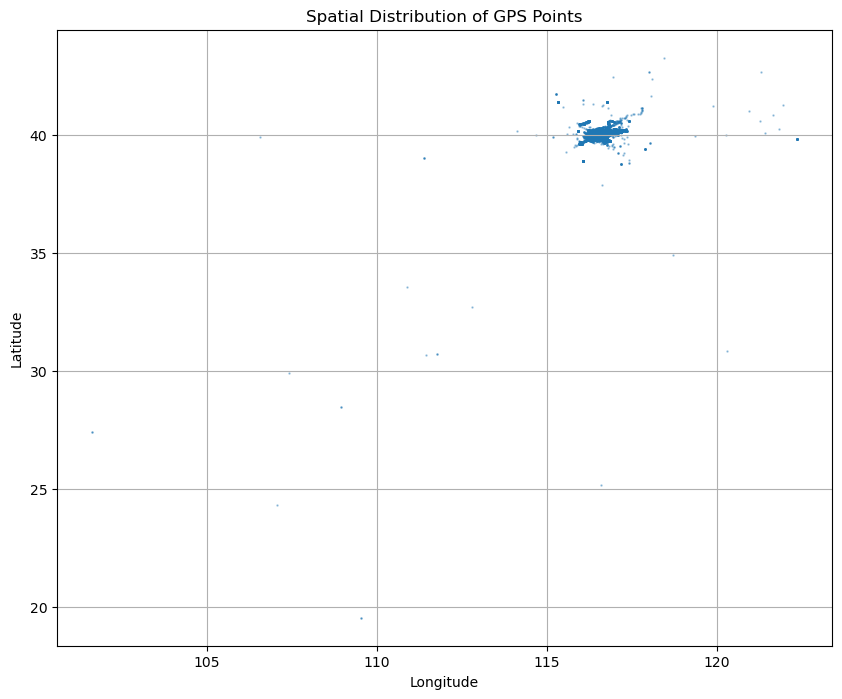

In [117]:
#1.scatter plot of majority of GPS observation which is around beijing
import matplotlib.pyplot as plt
plt.figure(figsize=(10,8))
plt.scatter(
     data["Longitude"],
     data["Latitude"],
     s=0.5,
     alpha=0.4
 )
plt.title("Spatial Distribution of GPS Points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show

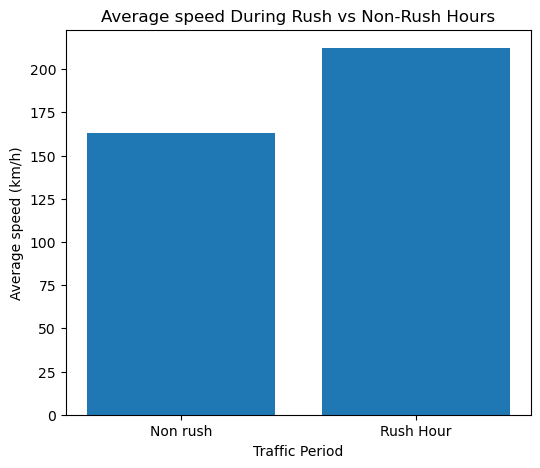

In [118]:
#2.BAR GRAPH avg speed:rush hr vs non rush hr
import matplotlib.pyplot as plt
avg_speed= data.groupby("RushHour")["Speed_kmh"].mean()
plt.figure(figsize=(6,5))
plt.bar(
    ["Non rush","Rush Hour"],
    avg_speed
)
plt.title("Average speed During Rush vs Non-Rush Hours")
plt.xlabel("Traffic Period")
plt.ylabel("Average speed (km/h)")
plt.show()

RushHour
0    15.126605
1    15.926143
Name: Speed_kmh, dtype: float64


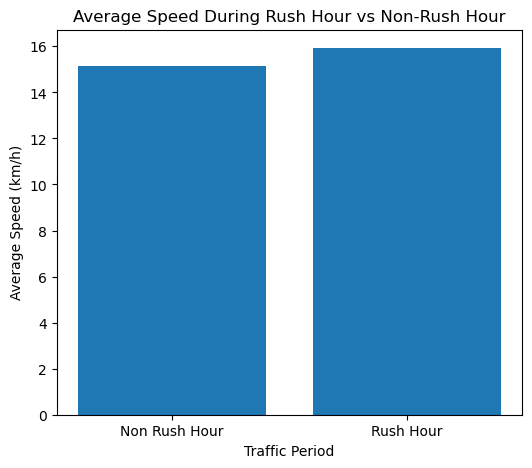

In [119]:
#Average Speed During Rush Hour vs Non-Rush Hour
avg_speed = (
    data.loc[data["Speed_kmh"] <= 120]
        .groupby("RushHour")["Speed_kmh"]
        .mean()
)

print(avg_speed)

plt.figure(figsize=(6,5))

plt.bar(
    ["Non Rush Hour", "Rush Hour"],
    avg_speed
)

plt.title("Average Speed During Rush Hour vs Non-Rush Hour")
plt.xlabel("Traffic Period")
plt.ylabel("Average Speed (km/h)")

plt.show()

In [120]:
print(data["RushHour"].value_counts())

RushHour
0    88502
1    49759
Name: count, dtype: int64


In [121]:
print(
    data.loc[data["Speed_kmh"] <= 120]
        .groupby("RushHour")["Speed_kmh"]
        .describe()
)

            count       mean        std  min       25%        50%        75%  \
RushHour                                                                       
0         88066.0  15.126605  17.314665  0.0  0.100809  10.480510  23.752656   
1         49490.0  15.926143  17.618981  0.0  0.267365  11.577308  24.026788   

                 max  
RushHour              
0         119.986450  
1         118.716121  


In [122]:
print(data["Speed_kmh"].quantile([0.95, 0.99, 0.999]))


0.950      52.757571
0.990      78.227043
0.999    1555.986709
Name: Speed_kmh, dtype: float64


In [123]:
stopped = data.groupby("RushHour")["Speed_kmh"].apply(lambda x: (x == 0).sum())

print(stopped)

RushHour
0    10520
1     5041
Name: Speed_kmh, dtype: int64


In [124]:
stopped_percent = data.groupby("RushHour")["Speed_kmh"].apply(lambda x: (x == 0).mean() * 100)

print(stopped_percent)

RushHour
0    11.886737
1    10.130831
Name: Speed_kmh, dtype: float64


In [125]:
#FEATURE VALIDATION FOR BETTER RESULTS
print(data["Time_Diff_Min"].describe())

count    138161.000000
mean          6.108115
std          38.076270
min           0.000000
25%           1.283333
50%           4.316667
75%           5.000000
max        3693.450000
Name: Time_Diff_Min, dtype: float64


In [126]:
print((data["Time_Diff_Min"] == 0).sum())

35


In [127]:
data.loc[
data["Time_Diff_Min"]==0,
["Taxi_ID","Timestamp","Prev_Timestamp","Distance_km","Speed_kmh"]
].head(10)

,Taxi_ID,Timestamp,Prev_Timestamp,Distance_km,Speed_kmh
14374,14,2008-02-07 04:57:37,2008-02-07 04:57:37,11.056958,NaN
17780,16,2008-02-04 13:59:51,2008-02-04 13:59:51,1437.662785,NaN
22482,18,2008-02-06 00:43:35,2008-02-06 00:43:35,1948.224280,NaN
23410,19,2008-02-04 06:01:10,2008-02-04 06:01:10,63.825482,NaN
27871,24,2008-02-02 23:58:11,2008-02-02 23:58:11,10.804977,NaN
35237,28,2008-02-02 15:08:48,2008-02-02 15:08:48,0.000852,NaN
35523,28,2008-02-02 22:56:24,2008-02-02 22:56:24,0.001112,NaN
35992,28,2008-02-03 11:56:40,2008-02-03 11:56:40,0.001112,NaN
36013,28,2008-02-03 12:36:53,2008-02-03 12:36:53,0.000853,NaN
36103,28,2008-02-03 15:10:48,2008-02-03 15:10:48,0.001112,NaN


In [128]:
print(data["Distance_km"].describe())

count    138161.000000
mean          1.352228
std          24.263717
min           0.000000
25%           0.006726
50%           0.224223
75%           1.157306
max        2364.384053
Name: Distance_km, dtype: float64


In [129]:
print("Negative Distance :",(data["Distance_km"]<0).sum())
print("Zero Distances :",(data["Distance_km"]==0).sum())

Negative Distance : 0
Zero Distances : 15561


In [130]:
data.nlargest(
    10,
    "Distance_km"
)[
    [
        "Taxi_ID",
        "Timestamp",
        "Distance_km",
        "Time_Diff_Min",
        "Speed_kmh"
    ]
]

,Taxi_ID,Timestamp,Distance_km,Time_Diff_Min,Speed_kmh
83680,60,2008-02-02 18:49:53,2364.384053,3.816667,3.716936e+04
83681,60,2008-02-02 18:54:53,2364.058805,5.000000,2.836871e+04
32956,26,2008-02-07 06:40:52,2362.622420,0.050000,2.835147e+06
32957,26,2008-02-07 06:45:51,2359.432792,4.983333,2.840789e+04
19687,16,2008-02-08 12:25:57,1975.883073,0.666667,1.778295e+05
19686,16,2008-02-08 12:25:17,1975.811460,0.150000,7.903246e+05
18869,16,2008-02-05 16:39:39,1958.478824,0.083333,1.410105e+06
18870,16,2008-02-05 16:39:49,1958.431335,0.166667,7.050353e+05
22482,18,2008-02-06 00:43:35,1948.224280,0.000000,NaN
22481,18,2008-02-06 00:43:35,1947.793156,5.000000,2.337352e+04


In [131]:
print("Distance > 1 km  :", (data["Distance_km"] > 1).sum())
print("Distance > 5 km  :", (data["Distance_km"] > 5).sum())
print("Distance > 10 km :", (data["Distance_km"] > 10).sum())
print("Distance > 50 km :", (data["Distance_km"] > 50).sum())
print("Distance >100 km :", (data["Distance_km"] > 100).sum())
print("Distance >500 km :", (data["Distance_km"] > 500).sum())

Distance > 1 km  : 38886
Distance > 5 km  : 3432
Distance > 10 km : 788
Distance > 50 km : 152
Distance >100 km : 78
Distance >500 km : 34


In [132]:
large_jumps = data.loc[
    data["Distance_km"] > 50,
    [
        "Taxi_ID",
        "Timestamp",
        "Prev_Timestamp",
        "Distance_km",
        "Time_Diff_Min",
        "Speed_kmh"
    ]
]

print(large_jumps.head(20))

       Taxi_ID           Timestamp      Prev_Timestamp  Distance_km  \
3383         3 2008-02-08 12:00:07 2008-02-08 11:55:26   115.256964   
3384         3 2008-02-08 12:00:25 2008-02-08 12:00:07   115.899987   
4899         6 2008-02-02 17:45:51 2008-02-02 17:39:51    67.182490   
4900         6 2008-02-02 17:51:51 2008-02-02 17:45:51    67.576586   
4903         6 2008-02-02 18:24:02 2008-02-02 18:06:02   136.410549   
5022         6 2008-02-03 08:07:32 2008-02-03 07:44:24   209.700605   
5023         6 2008-02-03 08:21:02 2008-02-03 08:07:32   211.898313   
5113         6 2008-02-03 21:15:07 2008-02-03 21:09:52    95.651811   
5116         6 2008-02-03 21:48:09 2008-02-03 21:42:09    93.351646   
5282         6 2008-02-05 13:15:31 2008-02-05 13:09:31    64.259180   
5286         6 2008-02-05 14:45:31 2008-02-05 13:43:32    82.991913   
5297         6 2008-02-05 16:05:47 2008-02-05 15:59:47    88.780546   
5300         6 2008-02-05 16:23:47 2008-02-05 16:17:47    52.662812   
5431  

In [133]:
#bearing validation
print(data["Bearing"].describe())

count    138161.000000
mean        157.317115
std         113.050254
min           0.000000
25%          60.514227
50%         160.769328
75%         264.206497
max         359.999961
Name: Bearing, dtype: float64


In [134]:
print("Bearing < 0   :", (data["Bearing"] < 0).sum())
print("Bearing > 360 :", (data["Bearing"] > 360).sum())

Bearing < 0   : 0
Bearing > 360 : 0


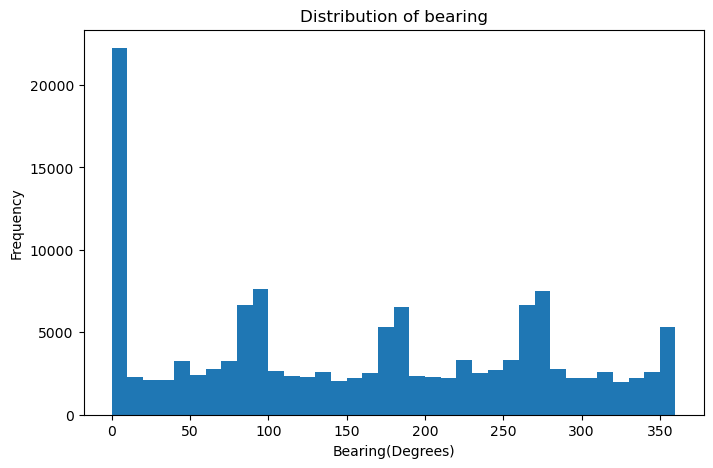

In [135]:
plt.figure(figsize=(8,5))
plt.hist(data["Bearing"].dropna(),bins=36)
plt.title("Distribution of bearing")
plt.xlabel("Bearing(Degrees)")
plt.ylabel("Frequency")
plt.show()

In [136]:
print(data[data["Distance_km"] > 10]["Time_Diff_Min"].describe())

print(data[data["Distance_km"] > 50]["Time_Diff_Min"].describe())

print(data[data["Distance_km"] > 100]["Time_Diff_Min"].describe())

count     788.000000
mean       61.619797
std       177.921943
min         0.000000
25%         5.000000
50%        10.000000
75%        26.779167
max      1588.300000
Name: Time_Diff_Min, dtype: float64
count     152.000000
mean       67.271382
std       245.639379
min         0.000000
25%         1.658333
50%         5.000000
75%         9.983333
max      1588.300000
Name: Time_Diff_Min, dtype: float64
count      78.000000
mean       48.054274
std       180.002373
min         0.000000
25%         0.654167
50%         5.000000
75%        13.162500
max      1472.800000
Name: Time_Diff_Min, dtype: float64


In [137]:
#validating gps anomaly,looking for better formula
print("Current GPS anomalies:", data["GPS_Anomaly"].sum())


Current GPS anomalies: 570


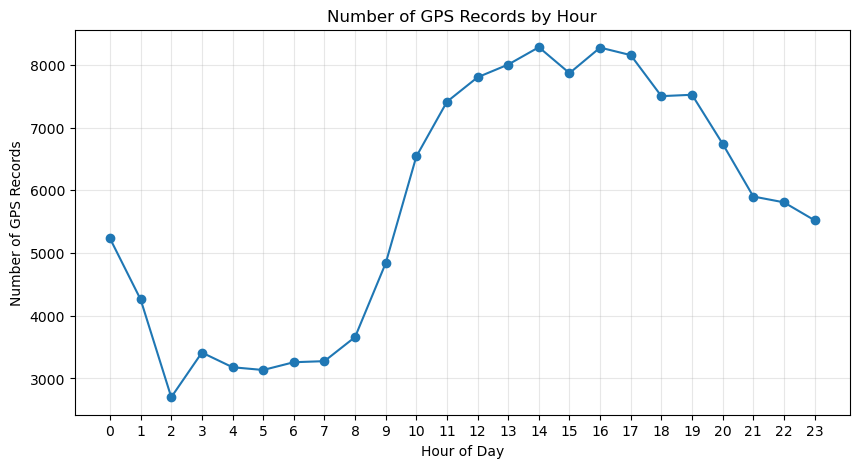

In [138]:
#Graph 1: Hourly Activity,
plt.figure(figsize=(10,5))

hourly_activity = data["Hour"].value_counts().sort_index()

plt.plot(
    hourly_activity.index,
    hourly_activity.values,
    marker="o"
)

plt.title("Number of GPS Records by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of GPS Records")

plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

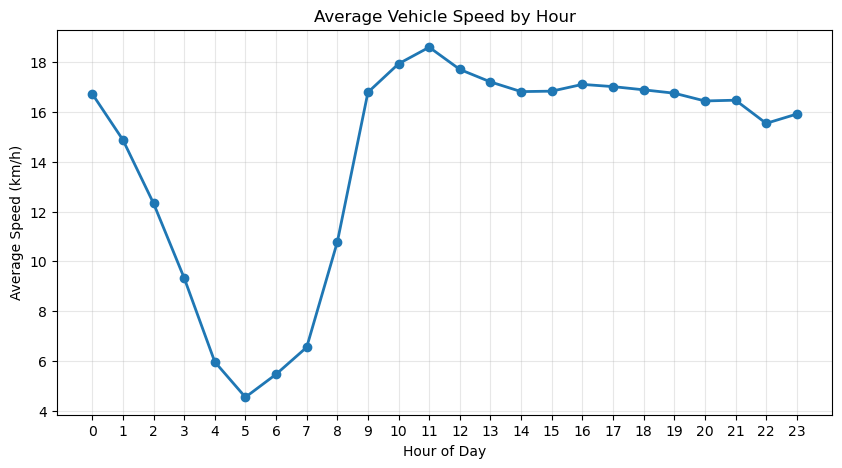

In [139]:
#Graph 2: Average Speed by Hour
# Remove unrealistic speeds only for visualization
speed_data = data[data["Speed_kmh"] <= 120]

# Calculate average speed for each hour
hourly_speed = speed_data.groupby("Hour")["Speed_kmh"].mean()

plt.figure(figsize=(10,5))

plt.plot(
    hourly_speed.index,
    hourly_speed.values,
    marker="o",
    linewidth=2
)

plt.title("Average Vehicle Speed by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Speed (km/h)")

plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

In [140]:
#aggregtaion table
speed_data.groupby("Hour")["Speed_kmh"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Hour,,,,
0,5217,16.723622,12.700153,18.563952
1,4250,14.876906,5.237320,18.916015
2,2695,12.329162,0.234101,18.490709
3,3399,9.332868,0.066717,17.391850
4,3132,5.962804,0.043103,14.413340
5,3129,4.542739,0.031385,12.425812
6,3208,5.463642,0.033376,15.251095
7,3233,6.548213,0.028571,16.079145
8,3638,10.773750,0.088219,19.442768


Hour
0     34.391130
1     45.162048
2     55.518519
3     66.412661
4     76.117055
5     82.067645
6     80.386740
7     77.068702
8     64.416507
9     43.229274
10    29.106760
11    21.387127
12    17.472119
13    19.990005
14    22.463768
15    20.465235
16    17.839014
17    16.360069
18    17.333333
19    17.854294
20    21.023739
21    26.288136
22    28.345101
23    31.860170
Name: Is_Idle, dtype: float64


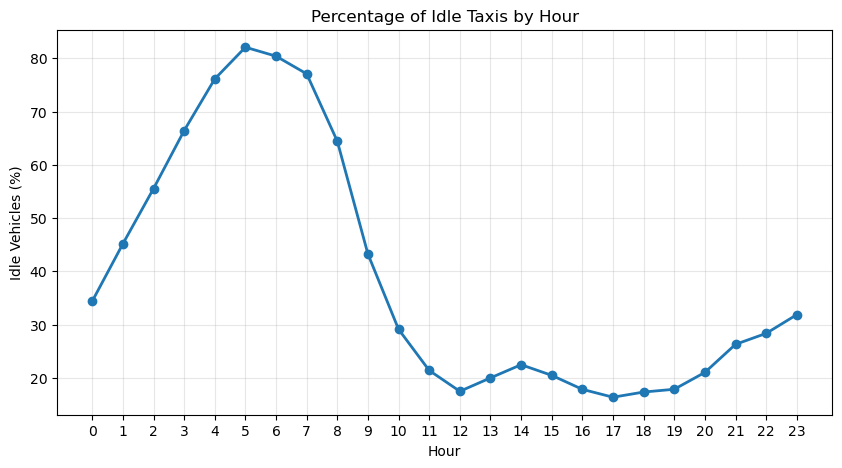

In [141]:
#
idle_by_hour = data.groupby("Hour")["Is_Idle"].mean() * 100

print(idle_by_hour)

plt.figure(figsize=(10,5))

plt.plot(
    idle_by_hour.index,
    idle_by_hour.values,
    marker="o",
    linewidth=2
)

plt.title("Percentage of Idle Taxis by Hour")
plt.xlabel("Hour")
plt.ylabel("Idle Vehicles (%)")

plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

In [142]:
print(data.dtypes)

Taxi_ID                        int64
Timestamp             datetime64[ns]
Longitude                    float64
Latitude                     float64
Prev_Latitude                float64
Prev_Longitude               float64
Prev_Timestamp        datetime64[ns]
Latitude_rad                 float64
Longitude_rad                float64
Prev_Latitude_rad            float64
Prev_Longitude_rad           float64
Delta_Lat                    float64
Delta_Lon                    float64
a                            float64
c                            float64
Distance_km                  float64
Time_Diff_Min                float64
Speed_kmh                    float64
Is_Idle                        int64
Bearing                      float64
Hour                           int32
DayOfWeek                      int32
IsWeekend                      int64
RushHour                       int64
GPS_Anomaly                    int64
dtype: object


In [143]:
numeric_data = data.select_dtypes(include=["number"])

print(numeric_data.columns)

Index(['Taxi_ID', 'Longitude', 'Latitude', 'Prev_Latitude', 'Prev_Longitude',
       'Latitude_rad', 'Longitude_rad', 'Prev_Latitude_rad',
       'Prev_Longitude_rad', 'Delta_Lat', 'Delta_Lon', 'a', 'c', 'Distance_km',
       'Time_Diff_Min', 'Speed_kmh', 'Is_Idle', 'Bearing', 'Hour', 'DayOfWeek',
       'IsWeekend', 'RushHour', 'GPS_Anomaly'],
      dtype='object')


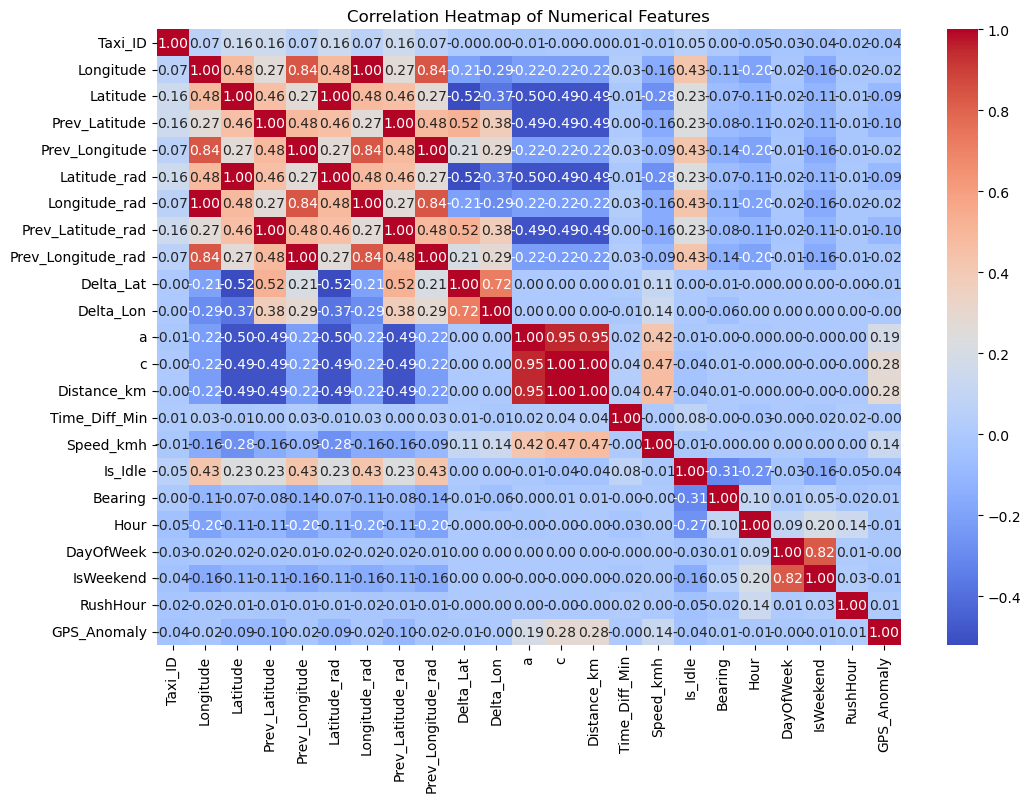

In [144]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")

plt.show()

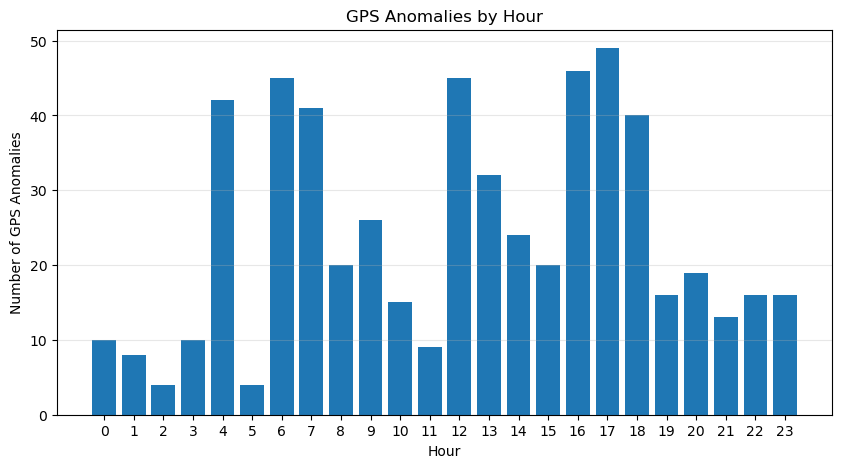

In [146]:
anomaly_hour = data.groupby("Hour")["GPS_Anomaly"].sum()

plt.figure(figsize=(10,5))

plt.bar(
    anomaly_hour.index,
    anomaly_hour.values
)

plt.title("GPS Anomalies by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of GPS Anomalies")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()

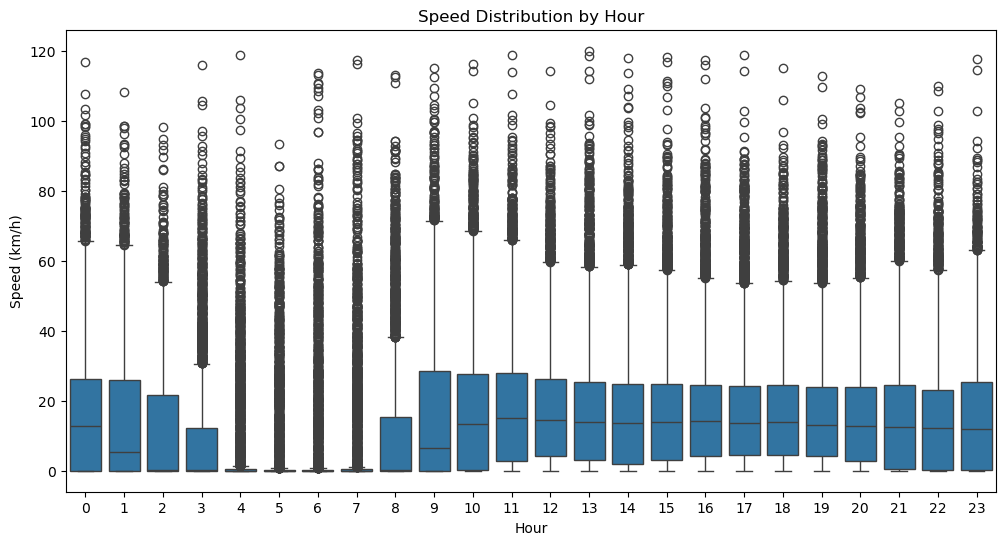

In [154]:
plt.figure(figsize=(12,6))

speed_data = data[data["Speed_kmh"] <= 120]

sns.boxplot(
    x="Hour",
    y="Speed_kmh",
    data=speed_data
)

plt.title("Speed Distribution by Hour")
plt.xlabel("Hour")
plt.ylabel("Speed (km/h)")

plt.show()

In [153]:
# ----------------------------------
# FINAL MODELING PIPELINE - START
# ----------------------------------

print("Data shape:", data.shape)

print("\nCurrent columns:")
print(data.columns.tolist())

print("\nRequired columns:")
required_columns = [
    "Longitude",
    "Latitude",
    "Speed_kmh",
    "Bearing",
    "Hour",
    "DayOfWeek",
    "IsWeekend",
    "RushHour"
]

for col in required_columns:
    print(f"{col}: {'OK' if col in data.columns else 'MISSING'}")

Data shape: (138261, 25)

Current columns:
['Taxi_ID', 'Timestamp', 'Longitude', 'Latitude', 'Prev_Latitude', 'Prev_Longitude', 'Prev_Timestamp', 'Latitude_rad', 'Longitude_rad', 'Prev_Latitude_rad', 'Prev_Longitude_rad', 'Delta_Lat', 'Delta_Lon', 'a', 'c', 'Distance_km', 'Time_Diff_Min', 'Speed_kmh', 'Is_Idle', 'Bearing', 'Hour', 'DayOfWeek', 'IsWeekend', 'RushHour', 'GPS_Anomaly']

Required columns:
Longitude: OK
Latitude: OK
Speed_kmh: OK
Bearing: OK
Hour: OK
DayOfWeek: OK
IsWeekend: OK
RushHour: OK


In [155]:
# ----------------------------------
# Final ML dataset
# ----------------------------------

model_features = [
    "Longitude",
    "Latitude",
    "Bearing",
    "Hour",
    "DayOfWeek",
    "IsWeekend",
    "RushHour"
]

# Keep only normal GPS observations
model_data = data[
    data["GPS_Anomaly"] == 0
].copy()

# Remove rows with missing values in required ML columns
model_data = model_data.dropna(
    subset=model_features + ["Speed_kmh"]
).copy()

# Remove invalid/infinite target values
model_data = model_data[
    np.isfinite(model_data["Speed_kmh"])
].copy()

X = model_data[model_features]
y = model_data["Speed_kmh"]

print("===== Final ML Dataset =====")
print("Original rows :", len(data))
print("Modeling rows :", len(model_data))
print("Removed rows  :", len(data) - len(model_data))

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nNaNs in X:", X.isna().sum().sum())
print("NaNs in y:", y.isna().sum())

print("\nTarget statistics:")
print(y.describe())

print("\nTarget range:", y.min(), "to", y.max())

===== Final ML Dataset =====
Original rows : 138261
Modeling rows : 137556
Removed rows  : 705

X shape: (137556, 7)
y shape: (137556,)

NaNs in X: 0
NaNs in y: 0

Target statistics:
count    137556.000000
mean         15.414263
std          17.428925
min           0.000000
25%           0.139447
50%          10.900573
75%          23.846314
max         119.986450
Name: Speed_kmh, dtype: float64

Target range: 0.0 to 119.98644960601219


In [156]:
# ----------------------------------
# Train / Test Split
# ----------------------------------

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("===== Train / Test Split =====")
print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)
print("Training Target   :", y_train.shape)
print("Testing Target    :", y_test.shape)

print("\nNaNs in X_train:", X_train.isna().sum().sum())
print("NaNs in X_test :", X_test.isna().sum().sum())
print("NaNs in y_train:", y_train.isna().sum())
print("NaNs in y_test :", y_test.isna().sum())

===== Train / Test Split =====
Training Features : (110044, 7)
Testing Features  : (27512, 7)
Training Target   : (110044,)
Testing Target    : (27512,)

NaNs in X_train: 0
NaNs in X_test : 0
NaNs in y_train: 0
NaNs in y_test : 0


In [157]:
# ----------------------------------
# Model 1: Linear Regression Baseline
# ----------------------------------

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("===== Clean Linear Regression =====")
print(f"MAE  : {mae_lr:.3f}")
print(f"RMSE : {rmse_lr:.3f}")
print(f"R²   : {r2_lr:.3f}")

===== Clean Linear Regression =====
MAE  : 12.500
RMSE : 16.782
R²   : 0.083


In [159]:
# ----------------------------------
# Model 2: Random Forest
# ----------------------------------

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("===== Clean Random Forest =====")
print(f"MAE  : {mae_rf:.3f}")
print(f"RMSE : {rmse_rf:.3f}")
print(f"R²   : {r2_rf:.3f}")

===== Clean Random Forest =====
MAE  : 8.037
RMSE : 12.303
R²   : 0.507
